# Notebook 01 — Selección espacial de estaciones candidatas

**TFM:** Evaluación de la influencia del componente espacial en la estimación de datos faltantes de precipitación diaria mediante modelos de Machine Learning aplicados a estaciones meteorológicas.

## Objetivo del notebook

Este notebook parte de un **punto de interés** de la zona de estudio y selecciona estaciones de precipitación cercanas a partir del dataset de Datos Abiertos Colombia con ayuda de la API Socrata.

La salida principal de este primer notebook será una tabla de **estaciones candidatas**, la cual servirá como entrada para el Notebook 02, donde se descargará la precipitación de dichas estaciones.

## Flujo

1. Definir punto de interés.
2. Consultar estaciones con registros de precipitación en Socrata.
3. Limpiar coordenadas.
4. Calcular distancia al punto de interés.
5. Seleccionar estaciones candidatas.
6. Guardar archivos intermedios para los siguientes notebooks.

# Instalación de Paquetes

Ejecuta esta celda solo si tu ambiente no tiene instalados los paquetes necesarios.

> Nota: `geopandas` es opcional en este notebook. Se usa únicamente para guardar un GeoPackage (`.gpkg`).

** VERIFICAR SI CON REQUIEREMENTS.TXT SE PUEDE HACER ESTE PROCESO Y SI ES ASÍ, PONERLO EXPLICADO :**

In [1]:
# Descomenta si necesitas instalar paquetes:
# !pip install pandas numpy sodapy matplotlib
# !pip install geopandas

# instalación de Librerias

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd



# Detectar carpetas del proyecto

---
> ℹ️ **Información**
>
> A continuación se construye la estructura de archivos a manejar en el proyecto

In [3]:


# Importamos la librería necesaria para el manejo de archivos

from pathlib import Path


# identificamos el nombre de la carpeta actual
carpeta_actual = Path.cwd()


# Comparamos si la carpeta actual hace parte de las carpetas del proyecto con el objetivo de encontrar la carpeta raiz
if carpeta_actual.name == 'notebooks':
    PROJECT_ROOT = carpeta_actual.parent
else:
    PROJECT_ROOT = carpeta_actual

# una vez determinada la capeta raiz 'PROJECT_ROOT' contruimos las demás carpetas del proyecto


folders = [
    PROJECT_ROOT / "data" / "raw",
    PROJECT_ROOT / "data" / "intermediate",
    PROJECT_ROOT / "data" / "processed",
    PROJECT_ROOT / "notebooks",
    PROJECT_ROOT / "output" / "tables",
    PROJECT_ROOT / "output" / "figures",
    PROJECT_ROOT / "scr"
]

# Con el siguiente bucle se crean de manera segura los directorios del proyecto

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True) # Parent = True crea las carpetas parent intermedias / exist_ok ignora las carpetas existentes



---
> ℹ️ **Información**
>
> A continuación se hará la consulta de las estaciones de por medio de la `API de SODA o Socrata V2` dispuesta en el portal de datos abiertos para **Colombia**.

In [4]:


# Punto de interés
LATITUD = 4.664
LONGITUD = -74.0769
punto_WKT = f"POINT ({LONGITUD} {LATITUD})"
print(punto_WKT)


# Parámetros de búsqueda
RADIO_METROS = 1000_000
LIMITE_ESTACIONES = 25

# Dataset de estaciones del IDEAM
DATASET_ID = "hp9r-jxuu"
URL_API = f"https://www.datos.gov.co/resource/{DATASET_ID}.json"

POINT (-74.0769 4.664)


Socrata indica expresamente que WKT y GeoJSON usan el orden longitud–latitud, mientras que within_circle() usa latitud–longitud.

In [5]:


consulta_soql = f"""
SELECT
    *,
    distance_in_meters(
        `ubicaci_n`,
        '{punto_WKT}'
    ) AS distancia_m
WHERE
    `ubicaci_n` IS NOT NULL

ORDER BY
    distancia_m ASC
LIMIT
    {LIMITE_ESTACIONES}
"""

print(consulta_soql)



SELECT
    *,
    distance_in_meters(
        `ubicaci_n`,
        'POINT (-74.0769 4.664)'
    ) AS distancia_m
WHERE
    `ubicaci_n` IS NOT NULL

ORDER BY
    distancia_m ASC
LIMIT
    25



In [6]:
import requests

parametros = {
    "$query": consulta_soql
}

respuesta = requests.get(
    URL_API,
    params=parametros,
    timeout=30
)

print("Código HTTP:", respuesta.status_code)
#print("Respuesta de la API:", respuesta.text)
print("Consulta enviada:")
print(consulta_soql)

respuesta.raise_for_status()

Código HTTP: 200
Consulta enviada:

SELECT
    *,
    distance_in_meters(
        `ubicaci_n`,
        'POINT (-74.0769 4.664)'
    ) AS distancia_m
WHERE
    `ubicaci_n` IS NOT NULL

ORDER BY
    distancia_m ASC
LIMIT
    25



Interpretación:

* Si ves [], la consulta fue válida, pero no encontró registros.

* Si ves un diccionario con "error" o "message", todavía hay un error en la consulta.

* Si el código es 200, la solicitud fue procesada correctamente.

* Si el código es 400, la consulta está mal construida.

In [7]:
datos_From_API = respuesta.json()
df_estaciones = pd.DataFrame(datos_From_API)
df_estaciones.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   codigo                25 non-null     object
 1   nombre                25 non-null     object
 2   categoria             25 non-null     object
 3   tecnologia            25 non-null     object
 4   estado                25 non-null     object
 5   departamento          25 non-null     object
 6   municipio             25 non-null     object
 7   ubicaci_n             25 non-null     object
 8   altitud               25 non-null     object
 9   longitud              25 non-null     object
 10  latitud               25 non-null     object
 11  fecha_instalacion     25 non-null     object
 12  area_operativa        25 non-null     object
 13  corriente             17 non-null     object
 14  area_hidrografica     25 non-null     object
 15  zona_hidrografica     25 non-null     obje

In [8]:
df_estaciones['distancia_m']= pd.to_numeric(df_estaciones['distancia_m'], errors="coerce")
df_estaciones['distancia_km'] = df_estaciones.distancia_m / 1000
df_estaciones.head()

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,ubicaci_n,altitud,longitud,...,fecha_instalacion,area_operativa,corriente,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,distancia_m,fecha_suspension,distancia_km
0,0048017060,TERESINA [48017060],Limnimétrica,Convencional,Activa,Amazonas,Leticia,"{'latitude': '-69.73333333', 'longitude': '-4....",75,-69.73333333,...,15/01/1977,Area Operativa 11 - Cundinamarca-Amazonas,AMAZONAS,Amazonas,Amazonas - Directos,Directos Río Amazonas (mi),ESTACIONES PARTICULARES,9.723880e+06,NaN,9723.879853
1,0048017010,LETICIA [48017010],Limnimétrica,Convencional,Activa,Amazonas,Leticia,"{'latitude': '-69.94272222', 'longitude': '-4....",120,-69.94272222,...,15/05/1986,Area Operativa 11 - Cundinamarca-Amazonas,AMAZONAS,Amazonas,Amazonas - Directos,Directos Río Amazonas (mi),INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,9.734235e+06,NaN,9734.235180
2,4801500132,RADIO SONDA LETICIA - AUT [4801500132],Radio Sonda,Automática con Telemetría,Suspendida,Amazonas,Leticia,"{'latitude': '-69.943055556', 'longitude': '-4...",82,-69.943055556,...,05/04/2016,Area Operativa 11 - Cundinamarca-Amazonas,NaN,Amazonas,Amazonas - Directos,Directos Río Amazonas (mi),INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,9.735067e+06,NaN,9735.066534
3,0048015050,AEROPUERTO VÁSQUEZ COBO - AUT [48015050],Sinóptica Principal,"Automática con Telemetría, Convencional",Activa,Amazonas,Leticia,"{'latitude': '-69.943095', 'longitude': '-4.19...",84,-69.943095,...,22/07/2009,Area Operativa 11 - Cundinamarca-Amazonas,NaN,Amazonas,Amazonas - Directos,Directos Río Amazonas (mi),INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,9.735076e+06,NaN,9735.075721
4,0048015020,RADIOSONDA AEROPUERTO VASQUEZ COBO [48015020],Radio Sonda,Automática sin Telemetría,Activa,Amazonas,Leticia,"{'latitude': '-69.94369444', 'longitude': '-4....",84,-69.94369444,...,15/03/1985,Area Operativa 11 - Cundinamarca-Amazonas,NaN,Amazonas,Amazonas - Directos,Directos Río Amazonas (mi),INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,9.735103e+06,NaN,9735.103350


In [9]:
fila = df_estaciones.iloc[0]

print("Estación:", fila["nombre"])
print("Departamento:", fila["departamento"])
print("Municipio:", fila["municipio"])

print("\nColumnas independientes:")
print("Longitud:", fila["longitud"])
print("Latitud:", fila["latitud"])

print("\nContenido de ubicaci_n:")
print(fila["ubicaci_n"])

Estación: TERESINA  [48017060]
Departamento: Amazonas
Municipio: Leticia

Columnas independientes:
Longitud: -69.73333333
Latitud: -4.283333333

Contenido de ubicaci_n:
{'latitude': '-69.73333333', 'longitude': '-4.283333333', 'human_address': '{"address": "", "city": "", "state": "", "zip": ""}'}


una vez envidenciado que las ubicaciones del data set no corresponden, se trae todo el data set para hacer la depuración directamente en python

In [10]:
consulta_soql_limitless = f"""
SELECT
    *

WHERE
    `ubicaci_n` IS NOT NULL

"""

print(consulta_soql_limitless)


SELECT
    *

WHERE
    `ubicaci_n` IS NOT NULL




In [11]:
parametros_limitless = {
    "$query": consulta_soql_limitless
}

respuesta_limitless = requests.get(
    URL_API,
    params=parametros_limitless,
    timeout=30
)

print("Código HTTP:", respuesta_limitless.status_code)
#print("Respuesta de la API:", respuesta.text)
print("Consulta enviada:")
print(consulta_soql_limitless)

respuesta_limitless.raise_for_status()

Código HTTP: 200
Consulta enviada:

SELECT
    *

WHERE
    `ubicaci_n` IS NOT NULL




In [12]:
datos_from_API2 = respuesta_limitless.json()
df_estaciones_raw = pd.DataFrame(datos_from_API2)
df_estaciones_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   codigo                1000 non-null   object
 1   nombre                1000 non-null   object
 2   categoria             1000 non-null   object
 3   tecnologia            1000 non-null   object
 4   estado                1000 non-null   object
 5   departamento          1000 non-null   object
 6   municipio             1000 non-null   object
 7   ubicaci_n             1000 non-null   object
 8   altitud               1000 non-null   object
 9   longitud              1000 non-null   object
 10  latitud               1000 non-null   object
 11  fecha_instalacion     987 non-null    object
 12  area_operativa        1000 non-null   object
 13  area_hidrografica     1000 non-null   object
 14  zona_hidrografica     1000 non-null   object
 15  subzona_hidrografica  1000 non-null   o

In [13]:
coordenadas_raw = pd.json_normalize(df_estaciones_raw["ubicaci_n"])
coordenadas_raw = coordenadas_raw.rename(columns={'longitude': 'longitud_raw','latitude':'latitud_raw'})
coordenadas_raw.head()

,latitud_raw,longitud_raw,human_address
0,-72.739228889,6.500608056,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
1,-73.316151944,4.974416111,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
2,-73.219595,4.735228889,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
3,-72.871813889,5.215341944,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
4,-73.41977778,4.815694444,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."


In [14]:
df_estaciones_raw = pd.concat([df_estaciones_raw, coordenadas_raw], axis=1)
df_estaciones_raw.head()

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,ubicaci_n,altitud,longitud,...,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension,latitud_raw,longitud_raw,human_address
0,0024030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,"{'latitude': '-72.739228889', 'longitude': '6....",2244,-72.739228889,...,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,-72.739228889,6.500608056,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
1,0035075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,"{'latitude': '-73.316151944', 'longitude': '4....",1742,-73.316151944,...,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,-73.316151944,4.974416111,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
2,0035070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,"{'latitude': '-73.219595', 'longitude': '4.735...",439,-73.219595,...,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,-73.219595,4.735228889,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
3,0035190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,"{'latitude': '-72.871813889', 'longitude': '5....",1129,-72.871813889,...,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,-72.871813889,5.215341944,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."
4,0035060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,"{'latitude': '-73.41977778', 'longitude': '4.8...",1845,-73.41977778,...,Area Operativa 11 - Cundinamarca-Amazonas,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,-73.41977778,4.815694444,"{""address"": """", ""city"": """", ""state"": """", ""zip""..."


In [15]:
columnas_coordenadas = [
    "latitud_raw",
    "longitud_raw",
    "latitud",
    "longitud",
]

for columna in columnas_coordenadas:
    df_estaciones_raw[columna] = pd.to_numeric(
        df_estaciones_raw[columna],
        errors="coerce",
    )

In [16]:
import plotly.express as px

# Mapa con las coordenadas extraídas de ubicaci_n
fig_raw = px.scatter_map(
    df_estaciones_raw,
    lat="latitud_raw",
    lon="longitud_raw",
    hover_name="nombre",
    hover_data=[
        "departamento",
        "municipio",
        "categoria",
    ],
    color_discrete_sequence=["fuchsia"],
)

# Mapa con las columnas independientes del dataset
fig_columnas = px.scatter_map(
    df_estaciones_raw,
    lat="latitud",
    lon="longitud",
    hover_name="nombre",
    hover_data=[
        "departamento",
        "municipio",
        "categoria",
    ],
    color_discrete_sequence=["fuchsia"],
)

In [17]:
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[
        [
            {"type": "map"},
            {"type": "map"},
        ]
    ],
    subplot_titles=(
        "Coordenadas extraídas de ubicaci_n",
        "Columnas longitud y latitud",
    ),
    horizontal_spacing=0.02,
)

In [18]:
fig = make_subplots(
    rows=1,
    cols=2,
    specs=[
        [
            {"type": "map"},
            {"type": "map"},
        ]
    ],
    subplot_titles=(
        "Coordenadas extraídas de ubicaci_n",
        "Columnas longitud y latitud",
    ),
    horizontal_spacing=0.02,
)

In [19]:
for traza in fig_raw.data:
    fig.add_trace(
        traza,
        row=1,
        col=1,
    )

for traza in fig_columnas.data:
    fig.add_trace(
        traza,
        row=1,
        col=2,
    )

In [20]:
capa_satelital = {
    "below": "traces",
    "sourcetype": "raster",
    "sourceattribution": "United States Geological Survey",
    "source": [
        (
            "https://basemap.nationalmap.gov/"
            "arcgis/rest/services/USGSImageryOnly/"
            "MapServer/tile/{z}/{y}/{x}"
        )
    ],
}

In [21]:
centro_colombia = {
    "lat": 4.5,
    "lon": -74.0,
}

centro_point = {
    "lat": -74.833,
    "lon": 5.616
}

fig.update_layout(
    map={
        "style": "white-bg",
        "layers": [capa_satelital],
        "center": centro_point,
        "zoom": 3,
    },
    map2={
        "style": "white-bg",
        "layers": [capa_satelital],
        "center": centro_colombia,
        "zoom": 3,
    },
    height=500,
    showlegend=False,
    margin={
        "r": 0,
        "t": 50,
        "l": 0,
        "b": 0,
    },
)

fig.show()

In [22]:
df_estaciones_raw.columns

Index(['codigo', 'nombre', 'categoria', 'tecnologia', 'estado', 'departamento',
       'municipio', 'ubicaci_n', 'altitud', 'longitud', 'latitud',
       'fecha_instalacion', 'area_operativa', 'area_hidrografica',
       'zona_hidrografica', 'subzona_hidrografica', 'entidad', 'corriente',
       'fecha_suspension', 'latitud_raw', 'longitud_raw', 'human_address'],
      dtype='object')

In [23]:
columnas = ['codigo', 'nombre', 'categoria', 'tecnologia', 'estado', 'departamento',
       'municipio', 'altitud', 'longitud', 'latitud',
       'fecha_instalacion', 'area_operativa', 'area_hidrografica',
       'zona_hidrografica', 'subzona_hidrografica', 'entidad', 'corriente',
       'fecha_suspension']

In [24]:
df_estaciones = df_estaciones_raw[columnas]
df_estaciones.head()

/usr/local/lib/python3.12/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning:

Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension
0,0024030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,2244,-72.739229,6.500608,15/06/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
1,0035075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,1742,-73.316152,4.974416,15/07/1982,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
2,0035070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,439,-73.219595,4.735229,15/09/1972,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
3,0035190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,1129,-72.871814,5.215342,15/11/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
4,0035060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,1845,-73.419778,4.815694,15/09/1964,Area Operativa 11 - Cundinamarca-Amazonas,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN


In [25]:
import geopandas as gpd #https://geopandas.org/en/stable/gallery/create_geopandas_from_pandas.html

gdf_estaciones = gpd.GeoDataFrame(
    df_estaciones,
    geometry=gpd.points_from_xy(
        df_estaciones["longitud"],
        df_estaciones["latitud"],
    ),
    crs="EPSG:4326",
)

gdf_estaciones.head()


/usr/local/lib/python3.12/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning:

Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension,geometry
0,0024030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,2244,-72.739229,6.500608,15/06/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (-72.73923 6.50061)
1,0035075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,1742,-73.316152,4.974416,15/07/1982,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (-73.31615 4.97442)
2,0035070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,439,-73.219595,4.735229,15/09/1972,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (-73.2196 4.73523)
3,0035190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,1129,-72.871814,5.215342,15/11/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (-72.87181 5.21534)
4,0035060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,1845,-73.419778,4.815694,15/09/1964,Area Operativa 11 - Cundinamarca-Amazonas,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (-73.41978 4.81569)


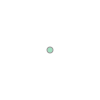

In [26]:
from shapely import Point # https://shapely.readthedocs.io/en/stable/geometry.html

punto_de_interes = Point(LONGITUD, LATITUD)
punto_de_interes



para hacer una medición más precisa, se hace la proyección de un sistema de coordenadas elipsoidal a uno de coordenadas planas

In [27]:
gdf_estaciones = gdf_estaciones.to_crs("EPSG:9377") # https://epsg.io/9377
gdf_estaciones.head()

/usr/local/lib/python3.12/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning:

Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension,geometry
0,0024030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,2244,-72.739229,6.500608,15/06/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (5028820.531 2276312.813)
1,0035075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,1742,-73.316152,4.974416,15/07/1982,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (4964965.675 2107674.184)
2,0035070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,439,-73.219595,4.735229,15/09/1972,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (4975657.107 2081240.957)
3,0035190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,1129,-72.871814,5.215342,15/11/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (5014199.574 2134288.243)
4,0035060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,1845,-73.419778,4.815694,15/09/1964,Area Operativa 11 - Cundinamarca-Amazonas,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN,POINT (4953471.252 2090142.337)


Las coordenadas tomadas de Google Maps para cualquier lugar de Colombia (en formato de latitud y longitud decimal) utilizan el sistema global WGS 84, cuyo código EPSG es EPSG:4326

In [28]:
from shapely.ops import transform
import pyproj

# 2. Definir el transformador de origen a destino (ej. WGS 84 a Magna-SIRGAS / Bogotá)
origen = "EPSG:4326"
destino = "EPSG:9377"
proyectar = pyproj.Transformer.from_crs(origen, destino, always_xy=True).transform

# 3. Reproyectar el punto
punto_reproyectado = transform(proyectar, punto_de_interes)

print(punto_reproyectado.x, punto_reproyectado.y)

4880602.962368504 2073458.0391020626


In [29]:
gdf_estaciones["distancia_m"] = gdf_estaciones.distance(punto_reproyectado)
gdf_estaciones = gdf_estaciones.sort_values("distancia_m",ascending=True)
gdf_estaciones.head()

/usr/local/lib/python3.12/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning:

Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension,geometry,distancia_m
775,2120700211,RIO SALITRE CARRERA 56B [2120700211],Limnimétrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2576,-74.076453,4.671118,01/11/2020,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,SALITRE,NaN,POINT (4880653.73 2074244.592),788.189205
671,2120000100,COLEGIO ALEMANIA SOLIDARIA [2120000100],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2556,-74.075434,4.652389,01/10/2015,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4880763.562 2072174.63),1293.417942
988,0021209090,AV 30 CALLE 68 [21209090],Limnimétrica,Convencional,Activa,Bogotá,"Bogotá, D.C",2676,-74.050000,4.666667,15/09/1990,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,EMPRESA DE ACUEDUCTO Y ALCANTARILLADO DE BOGOT...,CANAL SALITRE,NaN,POINT (4883586.169 2073748.235),2997.287963
443,0021205540,INST GEOFI ANDES [21205540],Climatológica Ordinaria,Convencional,Activa,Bogotá,"Bogotá, D.C",2600,-74.066667,4.633333,15/01/1942,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,ESTACIONES PARTICULARES,NaN,NaN,POINT (4881732.559 2070067.274),3573.971940
412,2120000170,COLEGIO SIMON RODRIGUEZ SEDE C [2120000170],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2702,-74.054350,4.640500,01/10/2019,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4883099.511 2070857.232),3605.128787


In [30]:
estaciones_cercanas = gdf_estaciones.head(20)
estaciones_cercanas

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension,geometry,distancia_m
775,2120700211,RIO SALITRE CARRERA 56B [2120700211],Limnimétrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2576,-74.076453,4.671118,01/11/2020,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,SALITRE,NaN,POINT (4880653.73 2074244.592),788.189205
671,2120000100,COLEGIO ALEMANIA SOLIDARIA [2120000100],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2556,-74.075434,4.652389,01/10/2015,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4880763.562 2072174.63),1293.417942
988,0021209090,AV 30 CALLE 68 [21209090],Limnimétrica,Convencional,Activa,Bogotá,"Bogotá, D.C",2676,-74.050000,4.666667,15/09/1990,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,EMPRESA DE ACUEDUCTO Y ALCANTARILLADO DE BOGOT...,CANAL SALITRE,NaN,POINT (4883586.169 2073748.235),2997.287963
443,0021205540,INST GEOFI ANDES [21205540],Climatológica Ordinaria,Convencional,Activa,Bogotá,"Bogotá, D.C",2600,-74.066667,4.633333,15/01/1942,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,ESTACIONES PARTICULARES,NaN,NaN,POINT (4881732.559 2070067.274),3573.971940
412,2120000170,COLEGIO SIMON RODRIGUEZ SEDE C [2120000170],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2702,-74.054350,4.640500,01/10/2019,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4883099.511 2070857.232),3605.128787
461,2120000135,COLEGIO MANUEL ELKIN PATARROYO [2120000135],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2672,-74.064390,4.618230,01/10/2018,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4881982.515 2068397.796),5244.923986
241,0021205290,EDIFICIO SAMPER [21205290],Climatológica Ordinaria,Convencional,Suspendida,Bogotá,"Bogotá, D.C",2570,-74.083333,4.616667,15/01/1944,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,MINISTERIO DE AGRICULTURA,NaN,15/01/1950,POINT (4879881.606 2068228.198),5279.355342
476,0021205600,VELODROMO 1 D MAYO [21205600],Meteorológica Especial,Convencional,Suspendida,Bogotá,"Bogotá, D.C",2650,-74.066667,4.616667,15/03/1986,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,15/06/1993,POINT (4881729.794 2068225.407),5352.587384
413,0021200230,SAN DIEGO [21200230],Pluviométrica,Convencional,Activa,Bogotá,"Bogotá, D.C",2700,-74.066667,4.616667,15/12/1945,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,EMPRESA DE ACUEDUCTO Y ALCANTARILLADO DE BOGOT...,NaN,NaN,POINT (4881729.794 2068225.407),5352.587384
573,0021206890,CERRO CAZADORES [21206890],Climatológica Ordinaria,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",3182,-74.028610,4.665770,01/09/2007,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,FONDO DE PREVENCIÓN Y ATENCIÓN DE DESASTRES DE...,NaN,NaN,POINT (4885957.796 2073645.642),5358.118964


In [31]:
!pip install contextily

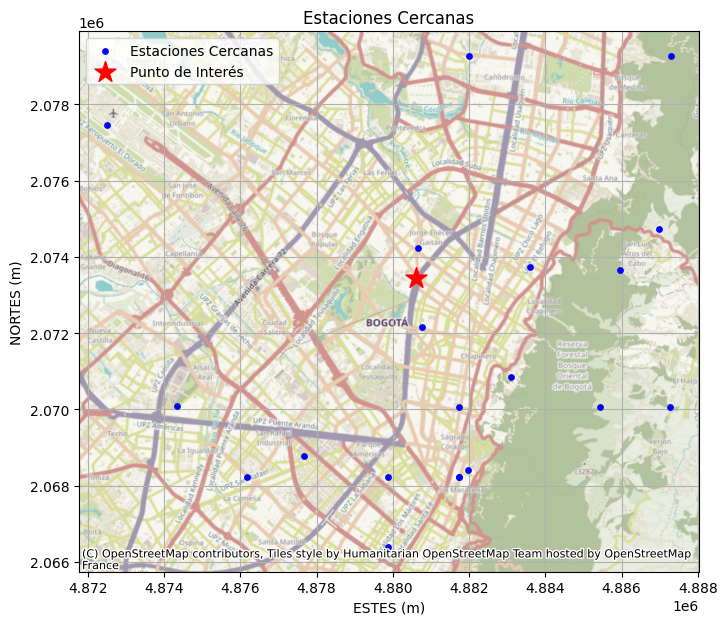

In [32]:
import contextily as cx # https://geopandas.org/en/stable/gallery/plotting_basemap_background.html - https://contextily.readthedocs.io/en/latest/providers_deepdive.html
fig, ax = plt.subplots(figsize=(8, 8))

estaciones_cercanas.plot(
    ax=ax,
    marker="o",
    color="blue",
    label="Estaciones Cercanas",
    markersize=15,
    zorder = 2 # https://matplotlib.org/3.1.1/gallery/misc/zorder_demo.html
    )

# Convert punto_reproyectado (shapely Point) to a GeoSeries for plotting
ax.scatter(
    punto_reproyectado.x,
    punto_reproyectado.y,
    marker="*",
    color="red",
    label="Punto de Interés",
    s=250,
    zorder = 1)


cx.add_basemap(ax, crs=estaciones_cercanas.crs, source=cx.providers.OpenStreetMap.HOT)

ax.set_title("Estaciones Cercanas")
ax.set_xlabel("ESTES (m)")
ax.set_ylabel("NORTES (m)")
ax.grid(True)
ax.legend()
plt.show()

# Revisión de atributos relevantes - Análisis Exploratorio (EDA)

Revision de estaciones duplicadas

In [33]:
diplicadiniha = estaciones_cercanas.duplicated().sum()
diplicadiniha

np.int64(0)

In [34]:

def buscar_estaciones_dupli(gdf_a_analizar):
    duplicadas = gdf_a_analizar[gdf_a_analizar.duplicated(subset="nombre",keep=False)]
    return duplicadas

In [35]:
estaciones_duplicadas = buscar_estaciones_dupli(estaciones_cercanas)
estaciones_duplicadas

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension,geometry,distancia_m


In [36]:
estaciones_candidatas = estaciones_cercanas.drop_duplicates(subset="nombre",keep='first')
estaciones_candidatas.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 20 entries, 775 to 893
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   codigo                20 non-null     object  
 1   nombre                20 non-null     object  
 2   categoria             20 non-null     object  
 3   tecnologia            20 non-null     object  
 4   estado                20 non-null     object  
 5   departamento          20 non-null     object  
 6   municipio             20 non-null     object  
 7   altitud               20 non-null     object  
 8   longitud              20 non-null     float64 
 9   latitud               20 non-null     float64 
 10  fecha_instalacion     20 non-null     object  
 11  area_operativa        20 non-null     object  
 12  area_hidrografica     20 non-null     object  
 13  zona_hidrografica     20 non-null     object  
 14  subzona_hidrografica  20 non-null     object  
 15  en

No todas las estaciones registran las precipitaciones, a continuación, se presenta un listados de estaciones que no debería ser tenidas en cuenta para el analisis de precipitacion ya que no registran este fenómeno.

In [37]:
categorias = df_estaciones_raw["categoria"].unique()
print(categorias)

['Pluviométrica' 'Climatológica Principal' 'Pluviográfica' 'Limnimétrica'
 'Limnigráfica' 'Climatológica Ordinaria' 'Agrometeorológica' 'Ambiental'
 'Sinóptica Principal' 'Meteorológica Especial' 'Meteorologica Marina'
 'Radio Sonda' 'HidroMeteorologica' 'Sinóptica Secundaria']


Conservar
Pluviométrica
Pluviográfica
Climatológica Principal
Climatológica Ordinaria
Agrometeorológica
Sinóptica Principal
Sinóptica Secundaria

Estas categorías incluyen explícitamente observaciones de precipitación. Las pluviométricas están destinadas a medir la lluvia acumulada entre observaciones, normalmente una vez al día; las pluviográficas registran la precipitación de forma continua. Las estaciones climatológicas, agrometeorológicas y sinópticas también incorporan la precipitación dentro de sus programas de observación.

Omitir inicialmente
Limnimétrica
Limnigráfica
Radio Sonda
Ambiental
Meteorológica Marina

Las limnimétricas y limnigráficas están orientadas principalmente al comportamiento hidrológico y al nivel de las corrientes, no a producir series climatológicas de precipitación. Las estaciones de radiosonda miden variables de la atmósfera superior, como presión, temperatura, humedad y viento mediante globos meteorológicos. Las estaciones marinas o mareográficas se enfocan principalmente en el estado del mar, nivel, temperatura y salinidad.

En cuanto a Ambiental, la omitiría del filtro inicial porque esa denominación no garantiza que tenga una serie diaria de precipitación comparable con la red meteorológica convencional.

Mantener de forma condicional
Meteorológica Especial

Una estación meteorológica especial se instala para seguir un fenómeno o propósito particular, como heladas. Puede tener pluviómetro, pero no es seguro que cuente con una serie diaria de precipitación suficientemente extensa y homogénea.

In [38]:
categorias_filtro = [
    "Pluviométrica",
    "Pluviográfica",
    "Climatológica Principal",
    "Climatológica Ordinaria",
    "Agrometeorológica",
    "Sinóptica Principal",
    "Sinóptica Secundaria"
    ]

In [39]:
estaciones_cercanas = estaciones_cercanas.loc[estaciones_cercanas["categoria"].isin(categorias_filtro)]
estaciones_cercanas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 12 entries, 671 to 893
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   codigo                12 non-null     object  
 1   nombre                12 non-null     object  
 2   categoria             12 non-null     object  
 3   tecnologia            12 non-null     object  
 4   estado                12 non-null     object  
 5   departamento          12 non-null     object  
 6   municipio             12 non-null     object  
 7   altitud               12 non-null     object  
 8   longitud              12 non-null     float64 
 9   latitud               12 non-null     float64 
 10  fecha_instalacion     12 non-null     object  
 11  area_operativa        12 non-null     object  
 12  area_hidrografica     12 non-null     object  
 13  zona_hidrografica     12 non-null     object  
 14  subzona_hidrografica  12 non-null     object  
 15  en

In [40]:
estaciones_cercanas["fecha_instalacion_mod"] = pd.to_datetime(estaciones_cercanas["fecha_instalacion"],format="%d/%m/%Y",errors="coerce")
estaciones_cercanas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 12 entries, 671 to 893
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   codigo                 12 non-null     object        
 1   nombre                 12 non-null     object        
 2   categoria              12 non-null     object        
 3   tecnologia             12 non-null     object        
 4   estado                 12 non-null     object        
 5   departamento           12 non-null     object        
 6   municipio              12 non-null     object        
 7   altitud                12 non-null     object        
 8   longitud               12 non-null     float64       
 9   latitud                12 non-null     float64       
 10  fecha_instalacion      12 non-null     object        
 11  area_operativa         12 non-null     object        
 12  area_hidrografica      12 non-null     object        
 13  z

/usr/local/lib/python3.12/dist-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [41]:
estaciones_cercanas.head(12)

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,altitud,longitud,latitud,...,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension,geometry,distancia_m,fecha_instalacion_mod
671,2120000100,COLEGIO ALEMANIA SOLIDARIA [2120000100],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2556,-74.075434,4.652389,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4880763.562 2072174.63),1293.417942,2015-10-01
443,0021205540,INST GEOFI ANDES [21205540],Climatológica Ordinaria,Convencional,Activa,Bogotá,"Bogotá, D.C",2600,-74.066667,4.633333,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,ESTACIONES PARTICULARES,NaN,NaN,POINT (4881732.559 2070067.274),3573.971940,1942-01-15
412,2120000170,COLEGIO SIMON RODRIGUEZ SEDE C [2120000170],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2702,-74.054350,4.640500,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4883099.511 2070857.232),3605.128787,2019-10-01
461,2120000135,COLEGIO MANUEL ELKIN PATARROYO [2120000135],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2672,-74.064390,4.618230,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4881982.515 2068397.796),5244.923986,2018-10-01
241,0021205290,EDIFICIO SAMPER [21205290],Climatológica Ordinaria,Convencional,Suspendida,Bogotá,"Bogotá, D.C",2570,-74.083333,4.616667,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,MINISTERIO DE AGRICULTURA,NaN,15/01/1950,POINT (4879881.606 2068228.198),5279.355342,1944-01-15
413,0021200230,SAN DIEGO [21200230],Pluviométrica,Convencional,Activa,Bogotá,"Bogotá, D.C",2700,-74.066667,4.616667,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,EMPRESA DE ACUEDUCTO Y ALCANTARILLADO DE BOGOT...,NaN,NaN,POINT (4881729.794 2068225.407),5352.587384,1945-12-15
573,0021206890,CERRO CAZADORES [21206890],Climatológica Ordinaria,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",3182,-74.028610,4.665770,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,FONDO DE PREVENCIÓN Y ATENCIÓN DE DESASTRES DE...,NaN,NaN,POINT (4885957.796 2073645.642),5358.118964,2007-09-01
213,2120000120,COLEGIO GUSTAVO MORALES [2120000120],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2553,-74.064401,4.716619,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4881997.733 2079270.973),5977.925164,2016-11-01
261,2120000139,ESC. PEDAGOGICA EXPRIMENTAL [2120000139],Pluviométrica,Automática con Telemetría,Activa,Bogotá,"Bogotá, D.C",2905,-74.019270,4.675530,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,INSTITUTO DISTRITAL DE GESTIÓN DE RIESGOS Y CA...,NaN,NaN,POINT (4886994.995 2074722.72),6515.942241,2018-10-01
15,0021205380,HIPOTECHO [21205380],Climatológica Ordinaria,Convencional,Activa,Bogotá,"Bogotá, D.C",2550,-74.133333,4.633333,...,Area Operativa 11 - Cundinamarca-Amazonas,Magdalena Cauca,Alto Magdalena,Río Bogotá,EMPRESA DE ACUEDUCTO Y ALCANTARILLADO DE BOGOT...,NaN,NaN,POINT (4874339.915 2070078.741),7116.559493,1957-05-15


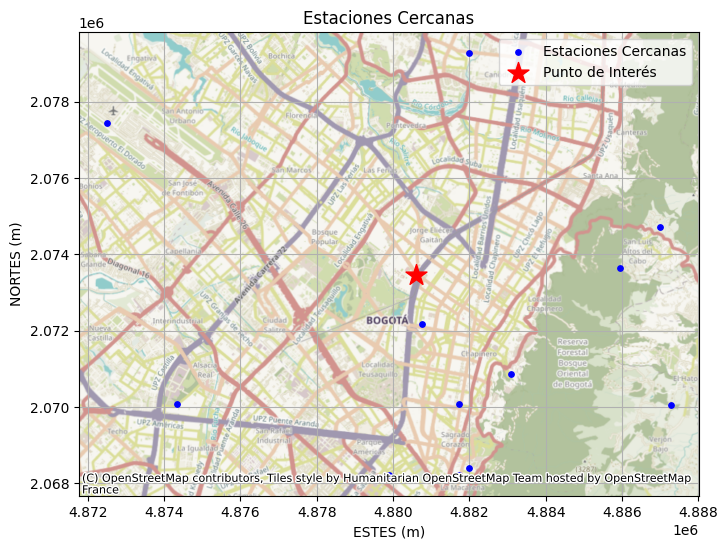

In [42]:
fig, ax = plt.subplots(figsize=(8, 8))

estaciones_cercanas.plot(
    ax=ax,
    marker="o",
    color="blue",
    label="Estaciones Cercanas",
    markersize=15,
    zorder = 2 # https://matplotlib.org/3.1.1/gallery/misc/zorder_demo.html
    )

# Convert punto_reproyectado (shapely Point) to a GeoSeries for plotting
ax.scatter(
    punto_reproyectado.x,
    punto_reproyectado.y,
    marker="*",
    color="red",
    label="Punto de Interés",
    s=250,
    zorder = 1)

cx.add_basemap(ax, crs=estaciones_cercanas.crs, source=cx.providers.OpenStreetMap.HOT) # https://xyzservices.readthedocs.io/en/stable/gallery.html

ax.set_title("Estaciones Cercanas")
ax.set_xlabel("ESTES (m)")
ax.set_ylabel("NORTES (m)")
ax.grid(True)
ax.legend()
plt.show()

Una vez esogidas y filtradas las estaciones, se proceden a almanecenar en la carptea correspondiente

In [43]:
estaciones_salida = estaciones_cercanas.copy()

Se guarda el archivo en GeoJson ya que se esta trabajando con un GeoDataFrame

In [44]:
RUTA_INTERIM = Path("/content/data/intermediate")

ruta_geojson = RUTA_INTERIM / "estaciones_candidatas.geojson"

estaciones_salida.to_file(
    ruta_geojson,
    driver="GeoJSON",
)